# 04 · What kind of crime, and when?

| Step | What happens |
|---|---|
| 1 | Break incidents down by crime type |
| 2 | Plot monthly incidents over the two years |
| 3 | Compare each month in 2023 with the same month in 2024 |

Police data is published by **month**, so this notebook can show seasonal patterns but not time of day or day of week.

In [1]:
import sys
from pathlib import Path

# Make the project's `src` package importable from inside notebooks/
sys.path.insert(0, str(Path.cwd().resolve().parent))

import calendar

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, plotting

In [2]:
crimes = pd.read_csv(config.CRIMES_CLEAN)
crimes["Month"] = pd.PeriodIndex(crimes["Month"], freq="M")
print(f"{len(crimes):,} incidents, {crimes['Month'].min()} to {crimes['Month'].max()}")

111,549 incidents, 2023-01 to 2024-12


## Step 1 · Crime type breakdown

Saved results\figures\crime_type_breakdown.png


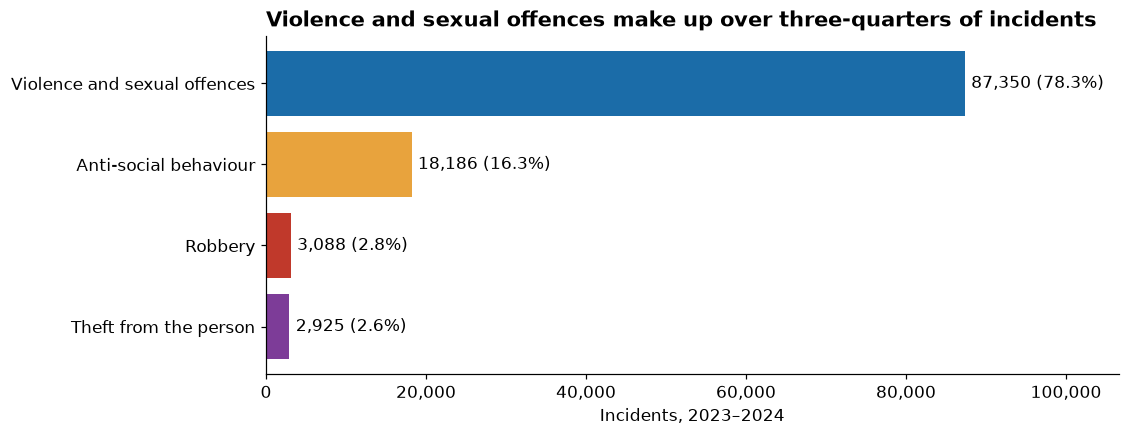

In [3]:
counts = crimes["Crime type"].value_counts().reindex(config.SAFETY_CRIMES)
share = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(counts.index[::-1], counts.values[::-1],
               color=[config.CRIME_COLOURS[t] for t in counts.index[::-1]])
for bar, n, pct in zip(bars, counts.values[::-1], share.values[::-1]):
    ax.text(bar.get_width() + 800, bar.get_y() + bar.get_height() / 2, f"{n:,} ({pct:.1f}%)", va="center")
ax.set_xlabel("Incidents, 2023–2024")
ax.set_xlim(0, counts.max() * 1.22)
ax.set_title("Violence and sexual offences make up over three-quarters of incidents")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plotting.save(fig, "crime_type_breakdown");

## Step 2 · Monthly incidents

Saved results\figures\monthly_trend.png


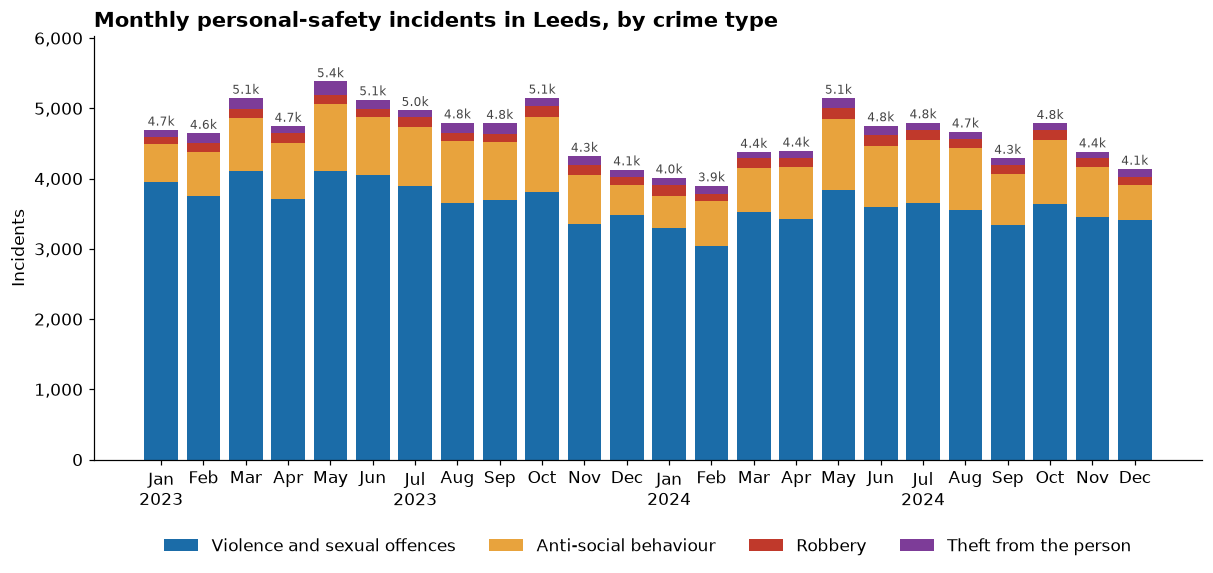

In [4]:
monthly = crimes.groupby(["Month", "Crime type"]).size().unstack(fill_value=0)[config.SAFETY_CRIMES]
monthly.to_csv(config.TABLES_DIR / "monthly_counts_by_type.csv")

fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(monthly))
bottom = np.zeros(len(monthly))
for crime_type in config.SAFETY_CRIMES:
    ax.bar(x, monthly[crime_type], bottom=bottom, color=config.CRIME_COLOURS[crime_type],
           label=crime_type, width=0.8)
    bottom += monthly[crime_type].to_numpy()
for xi, total in zip(x, bottom):
    ax.text(xi, total + 60, f"{total / 1000:.1f}k", ha="center", fontsize=8, color="#444")
ax.set_xticks(x, [m.strftime("%b\n%Y") if m.month in (1, 7) else m.strftime("%b") for m in monthly.index])
ax.set_ylabel("Incidents")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylim(0, bottom.max() * 1.12)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False)
ax.set_title("Monthly personal-safety incidents in Leeds, by crime type")
plotting.save(fig, "monthly_trend");

## Step 3 · Same month, year on year

In [5]:
totals = crimes.groupby("Month").size()
by_year = pd.DataFrame({year: totals[totals.index.year == year].to_numpy() for year in (2023, 2024)},
                       index=[calendar.month_abbr[m] for m in range(1, 13)])
by_year["Change (%)"] = ((by_year[2024] / by_year[2023] - 1) * 100).round(1)
by_year.to_csv(config.TABLES_DIR / "seasonal_comparison.csv")

annual = by_year[[2023, 2024]].sum()
print(f"2023: {annual[2023]:,}  |  2024: {annual[2024]:,}  |  change: {(annual[2024] / annual[2023] - 1):+.1%}")
print("Peak month:", by_year[2023].idxmax(), "(2023),", by_year[2024].idxmax(), "(2024)")
by_year

2023: 57,897  |  2024: 53,652  |  change: -7.3%
Peak month: May (2023), May (2024)


,2023,2024,Change (%)
Jan,4694,4013,-14.5
Feb,4647,3900,-16.1
Mar,5146,4378,-14.9
Apr,4748,4395,-7.4
May,5382,5146,-4.4
Jun,5125,4755,-7.2
Jul,4972,4797,-3.5
Aug,4796,4667,-2.7
Sep,4789,4292,-10.4
Oct,5149,4788,-7.0


Saved results\figures\seasonal_comparison.png


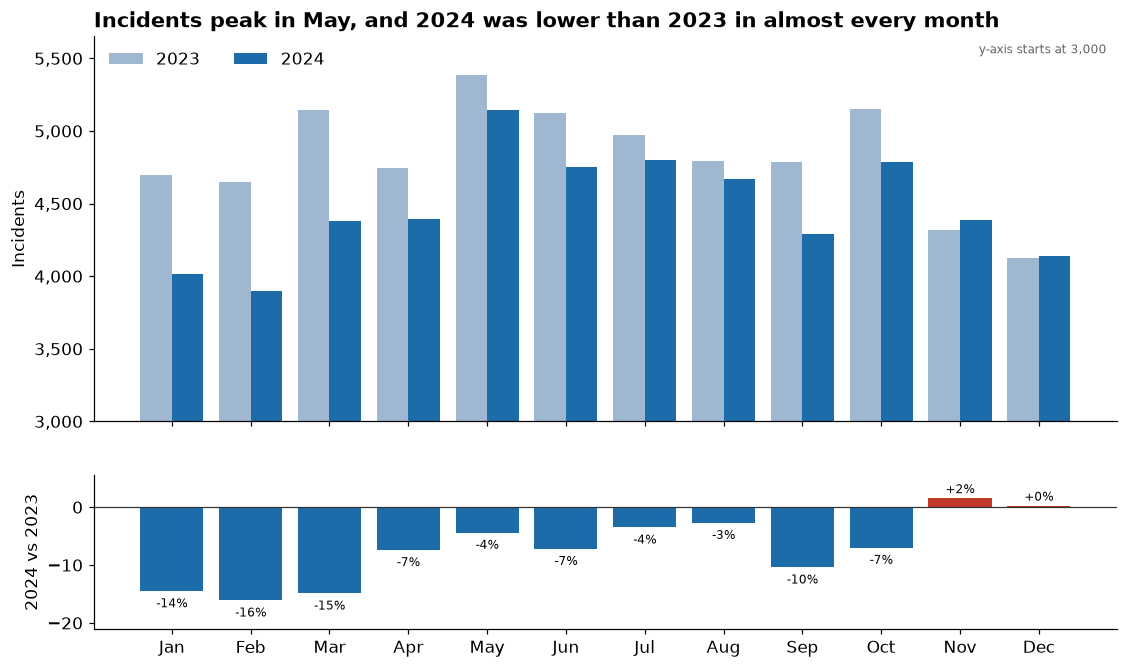

In [6]:
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
x = np.arange(12)
ax.bar(x - 0.2, by_year[2023], width=0.4, color="#9fb7d0", label="2023")
ax.bar(x + 0.2, by_year[2024], width=0.4, color="#1b6ca8", label="2024")
ax.set_ylabel("Incidents")
ax.set_ylim(3000, by_year[[2023, 2024]].to_numpy().max() * 1.05)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(frameon=False, ncol=2, loc="upper left")
ax.set_title("Incidents peak in May, and 2024 was lower than 2023 in almost every month")
ax.text(0.99, 0.98, "y-axis starts at 3,000", transform=ax.transAxes, ha="right", va="top", fontsize=8, color="#666")

change = by_year["Change (%)"]
ax2.bar(x, change, color=np.where(change < 0, "#1b6ca8", "#c0392b"))
ax2.axhline(0, color="#333", linewidth=0.8)
for xi, c in zip(x, change):
    ax2.text(xi, c - 1.2 if c < 0 else c + 0.4, f"{c:+.0f}%", ha="center", va="top" if c < 0 else "bottom", fontsize=8)
ax2.set_ylabel("2024 vs 2023")
ax2.set_ylim(change.min() - 5, max(change.max(), 0) + 4)
ax2.set_xticks(x, by_year.index)
plotting.save(fig, "seasonal_comparison");

**Summary:** violence and sexual offences dominate. Incidents peak in late spring and early summer and fall in winter, and the same pattern repeats in both years. Incidents fell in 2024, with the biggest drops in January to March.